# Populacja budynków z ortofotomapy i BDOT10k: proof of concept

Arkusz 6.148.12.04.2, okolice pl. Grunwaldzkiego, 800 × 500 m. Notatnik pokazuje dane i kartę budynku i działa bez klucza API. Pilot na całym arkuszu jest w `wyniki.ipynb`, a opis architektury i promptów w `docs/architektura.md`.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 88}}

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from shapely.geometry import box

from agenci import EKSPERYMENTY
from agenci.estymatory import objetosc_bdot
from agenci.karta import zbuduj_karte
from agenci.swiadkowie import tabela
from ortofoto.arkusze import czytaj, zasieg
from ortofoto.budynki import wczytaj_budynki, wczytaj_osm, wybierz

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
KOLORY = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # kategorie, zawsze w tej kolejności
NIEBIESKI = LinearSegmentedColormap.from_list("niebieski", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
TUSZ, SZARY = "#333333", "#b5b5b5"


def skala(ax, metry, loc="lower right"):
    pasek = AnchoredSizeBar(ax.transData, metry, f"{metry} m", loc, pad=0.4, borderpad=0.5, sep=3,
                            frameon=True, size_vertical=metry / 30)
    pasek.patch.set_alpha(0.8)
    ax.add_artist(pasek)


def podklad(bounds, res):
    """Rozjaśniony, szary wycinek arkusza N: tło, na którym kolory obrysów są czytelne."""
    img, ext = czytaj("N", bounds, res)
    return 255 - (255 - img.mean(2)) * 0.45, ext


bud = wczytaj_budynki()
osm = wczytaj_osm()
ARKUSZ = zasieg().bounds

## 1. Dane na jednym arkuszu

Ortofotomapa skośna z czterech kierunków, BDOT10k (obrysy z ewidencji, funkcja, kondygnacje, stan), wysokość ze skaningu laserowego i OSM (adres).

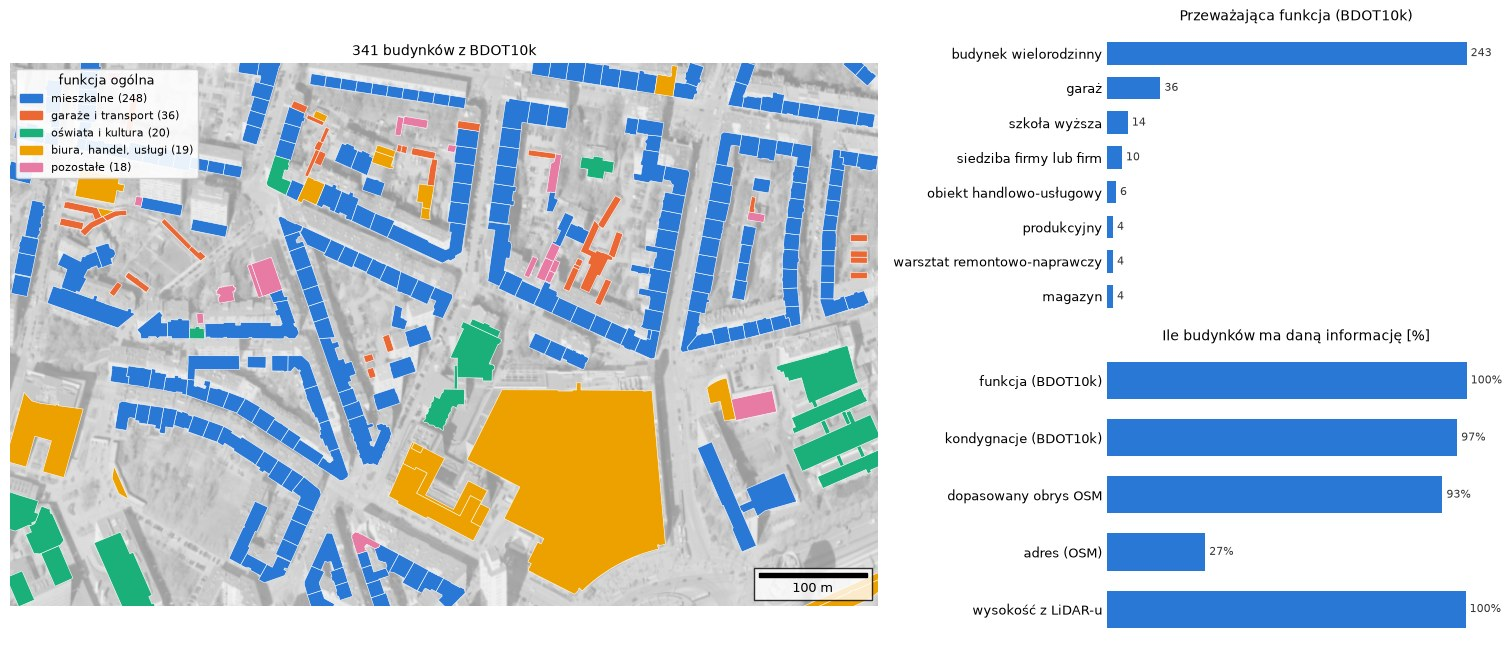

In [2]:
GRUPY = {"budynki mieszkalne": "mieszkalne", "budynki transportu i łączności": "garaże i transport",
         "budynki oświaty, nauki i kultury oraz budynki sportowe": "oświata i kultura",
         "budynki biurowe": "biura, handel, usługi", "budynki handlowo-usługowe": "biura, handel, usługi",
         "budynki szpitali i inne budynki opieki zdrowotnej": "biura, handel, usługi"}
KOLEJNOSC_GRUP = ["mieszkalne", "garaże i transport", "oświata i kultura", "biura, handel, usługi", "pozostałe"]
bud["grupa"] = bud.funkcja_ogolna.map(GRUPY).fillna("pozostałe")

fig, axs = plt.subplot_mosaic([["mapa", "funkcje"], ["mapa", "pokrycie"]], figsize=(15, 6.4), layout="constrained",
                              width_ratios=[2.3, 1])
img, ext = podklad(ARKUSZ, 1.0)
ax = axs["mapa"]
ax.imshow(img, extent=ext, cmap="gray", vmin=0, vmax=255)
for grupa, kolor in zip(KOLEJNOSC_GRUP, KOLORY):
    bud[bud.grupa == grupa].plot(ax=ax, color=kolor, edgecolor="white", linewidth=0.4)
ax.legend(handles=[Patch(color=k, label=f"{g} ({(bud.grupa == g).sum()})") for g, k in zip(KOLEJNOSC_GRUP, KOLORY)],
          title="funkcja ogólna", loc="upper left", fontsize=8, framealpha=0.9)
ax.set(title=f"{len(bud)} budynków z BDOT10k", xlim=ext[:2], ylim=ext[2:])
ax.set_axis_off()
skala(ax, 100)

funkcje = bud.funkcja.value_counts().head(8)[::-1]
pokrycie = pd.Series({"funkcja (BDOT10k)": bud.funkcja.notna().mean(),
                      "kondygnacje (BDOT10k)": bud.kondygnacje.notna().mean(),
                      "dopasowany obrys OSM": bud.osm_id.notna().mean(),
                      "adres (OSM)": bud["addr:street"].notna().mean(),
                      "wysokość z LiDAR-u": (bud.zrodlo_h == "LiDAR").mean()})[::-1] * 100
for nazwa, dane, tytul, format_ in [("funkcje", funkcje, "Przeważająca funkcja (BDOT10k)", "{:.0f}"),
                                    ("pokrycie", pokrycie, "Ile budynków ma daną informację [%]", "{:.0f}%")]:
    a = axs[nazwa]
    a.barh(dane.index, dane.values, color=KOLORY[0], height=0.65)
    for y, v in enumerate(dane.values):
        a.text(v, y, " " + format_.format(v), va="center", fontsize=8, color=TUSZ)
    a.set_title(tytul)
    a.tick_params(axis="y", length=0)
    a.set_xticks([])
    a.spines[["bottom", "left"]].set_visible(False)
plt.show()

## 2. BDOT10k i OSM razem

Ewidencja dzieli bloki na segmenty, a OSM często ma jeden obrys całego bloku. Segment dostaje z OSM adres, gdy obrys OSM pokrywa co najmniej połowę jego powierzchni.

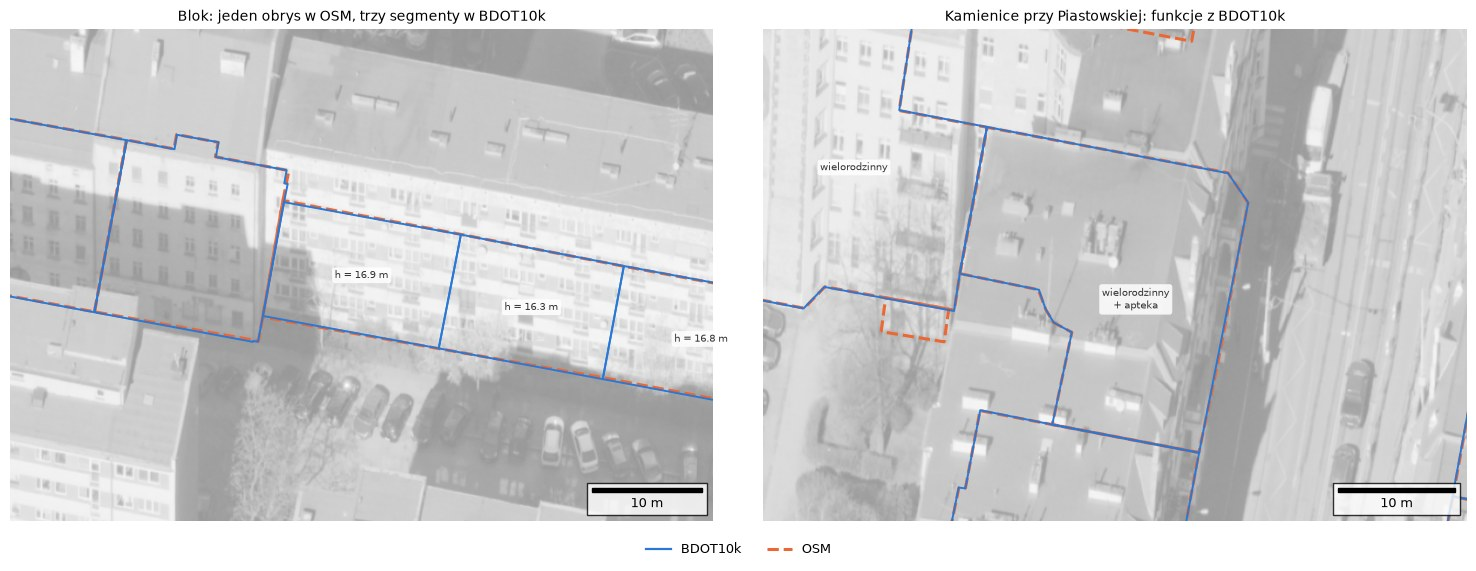

In [3]:
def zoom(ax, b, r, tytul, podpisy):
    cx, cy = b.geometry.centroid.coords[0]
    okno = (cx - r, cy - 0.7 * r, cx + r, cy + 0.7 * r)
    img, ext = podklad(okno, 0.1)
    ax.imshow(img, extent=ext, cmap="gray", vmin=0, vmax=255)
    w_oknie = box(*okno)
    osm[osm.intersects(w_oknie)].boundary.plot(ax=ax, color=KOLORY[1], linewidth=2.2, linestyle="--")
    bud[bud.intersects(w_oknie)].boundary.plot(ax=ax, color=KOLORY[0], linewidth=1.4)
    for seg in podpisy.itertuples():
        x, y = seg.geometry.representative_point().coords[0]
        if not w_oknie.contains(seg.geometry.representative_point()):
            continue
        ax.text(x, y, seg.podpis, ha="center", va="center", fontsize=7.5, color=TUSZ,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    ax.set(title=tytul, xlim=ext[:2], ylim=ext[2:])
    ax.set_axis_off()
    skala(ax, 10)


blok = bud[bud.osm_id == 101189011].copy()
blok["podpis"] = [f"h = {h:.1f} m" for h in blok.h]
kamienica = wybierz(bud, adres="Piastowska 36")
sasiedzi = bud[bud.intersects(kamienica.geometry.buffer(1))].copy()
sasiedzi["podpis"] = sasiedzi.funkcje.str.replace("budynek wielorodzinny", "wielorodzinny").str.replace("; ", "\n+ ")

fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")
zoom(axs[0], blok.iloc[1], 32, "Blok: jeden obrys w OSM, trzy segmenty w BDOT10k", blok)
zoom(axs[1], kamienica, 30, "Kamienice przy Piastowskiej: funkcje z BDOT10k", sasiedzi)
fig.legend(handles=[Line2D([], [], color=KOLORY[0], lw=1.6, label="BDOT10k"),
                    Line2D([], [], color=KOLORY[1], lw=2.2, ls="--", label="OSM")], loc="upper center",
           bbox_to_anchor=(0.5, -0.01), ncols=2, frameon=False)
plt.show()

## 3. Karta budynku

Deterministyczna część systemu: wszystko, co model dostaje o jednym budynku. Żółty obrys to podstawa, czerwony to dach przesunięty o 0,96 · h.

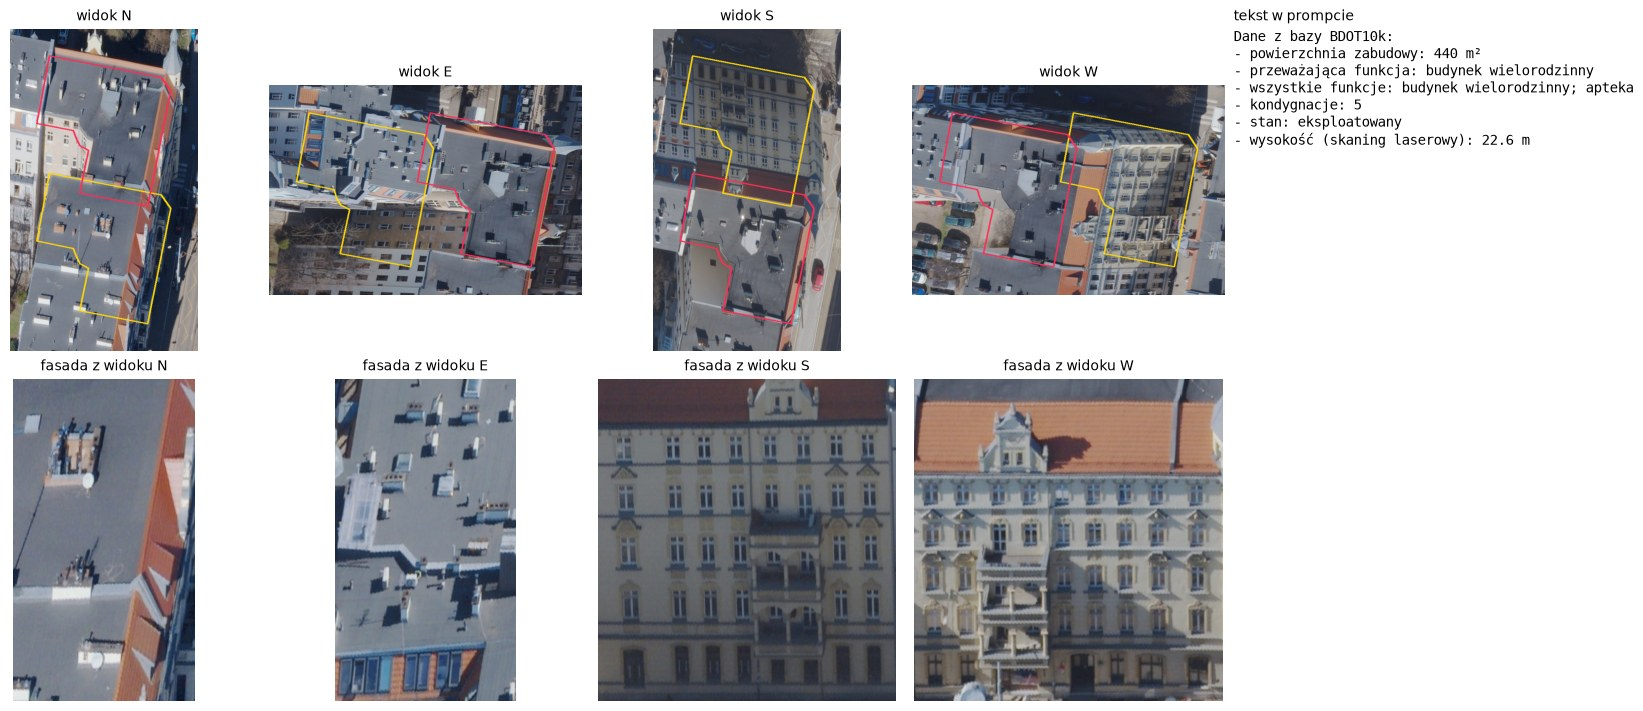

In [4]:
karta = zbuduj_karte(kamienica)
fig, axs = plt.subplot_mosaic([["N", "E", "S", "W", "rekord"], ["fN", "fE", "fS", "fW", "rekord"]], figsize=(17, 7),
                              layout="constrained", width_ratios=[1, 1, 1, 1, 0.9])
for kier in "NESW":
    axs[kier].imshow(karta.widoki[kier])
    axs[kier].set_title(f"widok {kier}")
    if kier in karta.fasady:
        axs["f" + kier].imshow(karta.fasady[kier])
    axs["f" + kier].set_title(f"fasada z widoku {kier}")
    for a in (axs[kier], axs["f" + kier]):
        a.set_axis_off()
axs["rekord"].text(0, 1, tabela(karta), va="top", fontsize=10, family="monospace", wrap=True)
axs["rekord"].set_title("tekst w prompcie", loc="left")
axs["rekord"].set_axis_off()
plt.show()

## 4. Baseline

Bez modelu: objętość budynków, które BDOT10k uznaje za mieszkalne i eksploatowane. Udział budynku w sumie to jego udział w populacji arkusza, gdyby gęstość wszędzie była taka sama.

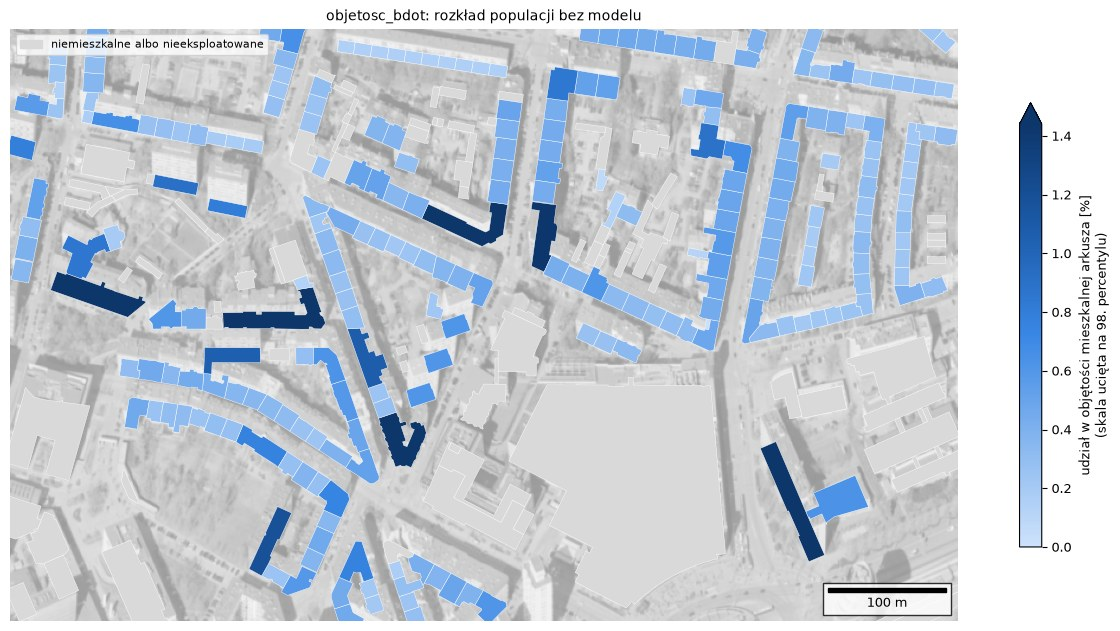

In [5]:
bud["objetosc_bdot"] = [objetosc_bdot(zbuduj_karte(b, obrazy=False)) for _, b in bud.iterrows()]
bud["udzial"] = bud.objetosc_bdot / bud.objetosc_bdot.sum() * 100
gora = np.percentile(bud.udzial[bud.udzial > 0], 98)

fig, ax = plt.subplots(figsize=(14, 6.2), layout="constrained")
img, ext = podklad(ARKUSZ, 1.0)
ax.imshow(img, extent=ext, cmap="gray", vmin=0, vmax=255)
bud[bud.udzial == 0].plot(ax=ax, color="#d9d9d9", edgecolor="white", linewidth=0.3)
bud[bud.udzial > 0].plot(ax=ax, column="udzial", cmap=NIEBIESKI, vmin=0, vmax=gora, edgecolor="white", linewidth=0.3,
                         legend=True, legend_kwds={"label": "udział w objętości mieszkalnej arkusza [%]\n"
                                                            "(skala ucięta na 98. percentylu)", "shrink": 0.75})
ax.legend(handles=[Patch(color="#d9d9d9", label="niemieszkalne albo nieeksploatowane")], loc="upper left", fontsize=8)
ax.set(title="objetosc_bdot: rozkład populacji bez modelu", xlim=ext[:2], ylim=ext[2:])
ax.set_axis_off()
skala(ax, 100)
plt.show()